In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

base_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(base_path):
    for file in files:
        if file in [
            "2011_09_26_drive_0009_sync.zip",
            "2011_09_26_calib.zip"
        ]:
            print("FOUND:", os.path.join(root, file))

In [5]:
import os

print("Google Drive folders:")

print(os.listdir("/content/drive/MyDrive"))

Google Drive folders:


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive'

In [6]:
import os

print("Content folders:")
print(os.listdir("/content"))

print("\nDrive folders:")
if os.path.exists("/content/drive"):
    print(os.listdir("/content/drive"))
else:
    print("Drive is not mounted")

Content folders:
['.config', 'sample_data']

Drive folders:
Drive is not mounted


In [7]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [8]:
import os

print(os.listdir("/content/drive/MyDrive"))

['photos', 'chani', 'acknowledgementSlip_S2266685908870_copy.pdf', 'Untitled Resume.pdf', 'Cover_Letter_BNY.pdf', 'Colab Notebooks', 'ML_Lab', 'Untitled Resume (2) (1).pdf', 'DeepMedSafe', 'Bayesian_Fraud_Project', 'Exponential_Waiting_Time_Project', 'Classroom', 'Community (2).pdf', 'Community (1).pdf', 'Community.pdf', 'project3_gas_sensor', 'Project_16_Kalman_Filter']


In [9]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.endswith(".zip") and (
            "2011_09_26_drive_0009_sync" in file
            or "2011_09_26_calib" in file
        ):
            print(os.path.join(root, file))

/content/drive/MyDrive/Project_16_Kalman_Filter/dataset/2011_09_26_calib.zip
/content/drive/MyDrive/Project_16_Kalman_Filter/dataset/2011_09_26_drive_0009_sync.zip


In [10]:
import os
import zipfile

base_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(base_path):
    for file in files:
        if file in ["2011_09_26_drive_0009_sync.zip", "2011_09_26_calib.zip"]:
            zip_path = os.path.join(root, file)
            extract_path = os.path.join(root, file.replace(".zip", ""))

            print("Extracting:", file)

            with zipfile.ZipFile(zip_path, 'r') as zip_ref:
                zip_ref.extractall(extract_path)

            print("Completed:", extract_path)

Extracting: 2011_09_26_calib.zip
Completed: /content/drive/MyDrive/Project_16_Kalman_Filter/dataset/2011_09_26_calib
Extracting: 2011_09_26_drive_0009_sync.zip
Completed: /content/drive/MyDrive/Project_16_Kalman_Filter/dataset/2011_09_26_drive_0009_sync


In [11]:
import os

dataset_path = "/content/drive/MyDrive/Project_16_Kalman_Filter/dataset"

print("Searching for OXTS GPS/IMU data...\n")

for root, dirs, files in os.walk(dataset_path):
    if "oxts" in root.lower():
        print("Folder:", root)
        for file in files[:5]:
            print("  ", file)

Searching for OXTS GPS/IMU data...

Folder: /content/drive/MyDrive/Project_16_Kalman_Filter/dataset/2011_09_26_drive_0009_sync/2011_09_26/2011_09_26_drive_0009_sync/oxts
   timestamps.txt
   dataformat.txt
Folder: /content/drive/MyDrive/Project_16_Kalman_Filter/dataset/2011_09_26_drive_0009_sync/2011_09_26/2011_09_26_drive_0009_sync/oxts/data
   0000000017.txt
   0000000154.txt
   0000000321.txt
   0000000149.txt
   0000000175.txt


In [12]:
import os
import glob

dataset_path = "/content/drive/MyDrive/Project_16_Kalman_Filter/dataset"

data_files = glob.glob(
    dataset_path + "/**/oxts/data/*.txt",
    recursive=True
)

data_files = sorted(data_files)

print("Total OXTS measurement files:", len(data_files))

if data_files:
    print("\nFirst measurement file:")
    print(data_files[0])

    with open(data_files[0], "r") as f:
        values = f.readline().strip().split()

    print("\nNumber of values:", len(values))
    print("First 10 values:", values[:10])
else:
    print("OXTS data files not found.")

Total OXTS measurement files: 447

First measurement file:
/content/drive/MyDrive/Project_16_Kalman_Filter/dataset/2011_09_26_drive_0009_sync/2011_09_26/2011_09_26_drive_0009_sync/oxts/data/0000000000.txt

Number of values: 30
First 10 values: ['49.009347760599', '8.4371344308375', '114.45652008057', '0.072242', '0.001566', '-0.2697266732051', '-2.9301818443449', '10.286884437741', '10.695750797331', '0.082893715568935']


In [14]:
import os
import glob
import pandas as pd

dataset_path = "/content/drive/MyDrive/Project_16_Kalman_Filter/dataset"

# Locate OXTS measurement files
data_files = sorted(glob.glob(
    dataset_path + "/**/oxts/data/*.txt",
    recursive=True
))

# KITTI OXTS column names
columns = [
    "lat", "lon", "alt", "roll", "pitch", "yaw",
    "vn", "ve", "vf", "vl", "vu",
    "ax", "ay", "az", "af", "al", "au",
    "wx", "wy", "wz", "wf", "wl", "wu",
    "pos_accuracy", "vel_accuracy", "navstat",
    "numsats", "posmode", "velmode", "orimode"
]

# Read measurements
records = []

for file in data_files:
    with open(file, "r") as f:
        values = list(map(float, f.read().split()))

    if len(values) != len(columns):
        raise ValueError(
            f"Unexpected number of values in {file}: {len(values)}"
        )

    records.append(values)

df = pd.DataFrame(records, columns=columns)

print("Dataset loaded successfully!")
print("Total records:", len(df))
print("Total columns:", len(df.columns))

display(df.head())

Dataset loaded successfully!
Total records: 447
Total columns: 30


,lat,lon,alt,roll,pitch,yaw,vn,ve,vf,vl,...,wf,wl,wu,pos_accuracy,vel_accuracy,navstat,numsats,posmode,velmode,orimode
0,49.009348,8.437134,114.456520,0.072242,0.001566,-0.269727,-2.930182,10.286884,10.695751,0.082894,...,0.016662,-0.036976,0.000604,0.428562,0.057983,4.0,7.0,4.0,4.0,0.0
1,49.009345,8.437150,114.453873,0.073139,-0.000124,-0.269609,-2.919715,10.304161,10.709611,0.068613,...,0.002734,-0.012760,0.001956,0.428562,0.057983,4.0,7.0,4.0,4.0,0.0
2,49.009342,8.437164,114.458748,0.069770,0.002527,-0.269658,-2.895219,10.327819,10.725885,0.039142,...,-0.026791,0.022720,0.000459,0.428562,0.057983,4.0,7.0,4.0,4.0,0.0
3,49.009340,8.437178,114.462502,0.069280,0.006679,-0.269507,-2.905630,10.325249,10.726179,0.050174,...,-0.004234,0.035775,0.002543,0.428562,0.057983,4.0,7.0,4.0,4.0,0.0
4,49.009337,8.437194,114.461815,0.068783,0.008822,-0.269148,-2.912686,10.314180,10.717372,0.062980,...,-0.005122,0.022146,0.003912,0.428562,0.057983,4.0,7.0,4.0,4.0,0.0


In [15]:
import numpy as np

# Earth's radius in metres
R = 6378137.0

# Use the first GPS measurement as the origin
lat0 = np.radians(df["lat"].iloc[0])
lon0 = np.radians(df["lon"].iloc[0])

# Convert latitude and longitude into local coordinates
lat = np.radians(df["lat"].values)
lon = np.radians(df["lon"].values)

df["x_gps"] = R * (lon - lon0) * np.cos(lat0)
df["y_gps"] = R * (lat - lat0)

print("GPS conversion completed!")
print(df[["lat", "lon", "x_gps", "y_gps"]].head())

print("\nDataset shape:", df.shape)

GPS conversion completed!
         lat       lon     x_gps     y_gps
0  49.009348  8.437134  0.000000  0.000000
1  49.009345  8.437150  1.130838 -0.321590
2  49.009342  8.437164  2.163013 -0.612029
3  49.009340  8.437178  3.192600 -0.904343
4  49.009337  8.437194  4.324981 -1.228129

Dataset shape: (447, 32)


In [16]:
import glob
import pandas as pd
import numpy as np
import os

dataset_path = "/content/drive/MyDrive/Project_16_Kalman_Filter/dataset"

# Find the KITTI OXTS timestamps file
timestamp_files = glob.glob(
    dataset_path + "/**/oxts/timestamps.txt",
    recursive=True
)

if not timestamp_files:
    raise FileNotFoundError("OXTS timestamps.txt was not found.")

timestamp_path = timestamp_files[0]

# Read timestamps
timestamps = pd.read_csv(
    timestamp_path,
    header=None,
    names=["timestamp"]
)

timestamps["timestamp"] = pd.to_datetime(
    timestamps["timestamp"],
    errors="coerce"
)

# Calculate time intervals
time_seconds = (
    timestamps["timestamp"] - timestamps["timestamp"].iloc[0]
).dt.total_seconds().to_numpy()

if len(time_seconds) != len(df):
    raise ValueError(
        f"Timestamp count ({len(time_seconds)}) "
        f"does not match dataset rows ({len(df)})."
    )

df["time"] = time_seconds

# Calculate time difference between consecutive measurements
df["dt"] = df["time"].diff()

# Use the KITTI eastward and northward velocity measurements
df["vx_measured"] = df["ve"]
df["vy_measured"] = df["vn"]

print("Time and velocity preparation completed!")
display(df[["time", "dt", "x_gps", "y_gps",
            "vx_measured", "vy_measured"]].head(10))

Time and velocity preparation completed!


,time,dt,x_gps,y_gps,vx_measured,vy_measured
0,0.000000,NaN,0.000000,0.000000,10.286884,-2.930182
1,0.109995,0.109995,1.130838,-0.321590,10.304161,-2.919715
2,0.210043,0.100048,2.163013,-0.612029,10.327819,-2.895219
3,0.310053,0.100011,3.192600,-0.904343,10.325249,-2.905630
4,0.419984,0.109931,4.324981,-1.228129,10.314180,-2.912686
5,0.520005,0.100020,5.352244,-1.520692,10.299324,-2.910275
6,0.630077,0.110072,6.480812,-1.841408,10.280017,-2.907223
7,0.730154,0.100077,7.511423,-2.128168,10.263403,-2.895542
8,0.830024,0.099870,8.550458,-2.407539,10.242210,-2.882770
9,0.940023,0.110000,9.693146,-2.713100,10.227178,-2.870334


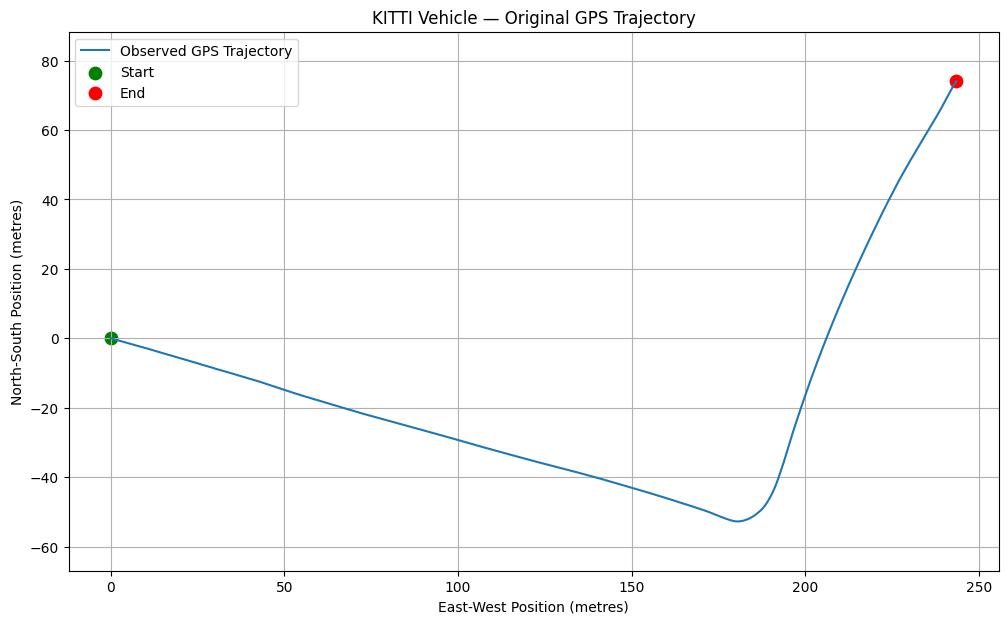

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.plot(
    df["x_gps"],
    df["y_gps"],
    label="Observed GPS Trajectory",
    linewidth=1.5
)

plt.scatter(
    df["x_gps"].iloc[0],
    df["y_gps"].iloc[0],
    color="green",
    label="Start",
    s=80
)

plt.scatter(
    df["x_gps"].iloc[-1],
    df["y_gps"].iloc[-1],
    color="red",
    label="End",
    s=80
)

plt.title("KITTI Vehicle — Original GPS Trajectory")
plt.xlabel("East-West Position (metres)")
plt.ylabel("North-South Position (metres)")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()

In [18]:
import numpy as np

# Average time interval between measurements
dt = df["dt"].median()

# State transition matrix
F = np.array([
    [1, 0, dt, 0],
    [0, 1, 0, dt],
    [0, 0, 1,  0],
    [0, 0, 0,  1]
])

# Measurement matrix
# We measure x, y, vx and vy
H = np.eye(4)

# Process noise covariance
sigma_acc = 1.0

G = np.array([
    [0.5 * dt**2, 0],
    [0, 0.5 * dt**2],
    [dt, 0],
    [0, dt]
])

Q = sigma_acc**2 * G @ G.T

# Measurement noise covariance
R = np.diag([
    3.0**2,    # GPS X variance
    3.0**2,    # GPS Y variance
    0.5**2,    # Velocity X variance
    0.5**2     # Velocity Y variance
])

# Initial state covariance
P = np.diag([10, 10, 5, 5])

print("State-space model created successfully!")
print("\nF - State Transition Matrix:\n", F)
print("\nH - Measurement Matrix:\n", H)
print("\nQ - Process Noise Covariance:\n", Q)
print("\nR - Measurement Noise Covariance:\n", R)
print("\nP - Initial Covariance:\n", P)

State-space model created successfully!

F - State Transition Matrix:
 [[1.         0.         0.10004254 0.        ]
 [0.         1.         0.         0.10004254]
 [0.         0.         1.         0.        ]
 [0.         0.         0.         1.        ]]

H - Measurement Matrix:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Q - Process Noise Covariance:
 [[2.50425682e-05 0.00000000e+00 5.00638386e-04 0.00000000e+00]
 [0.00000000e+00 2.50425682e-05 0.00000000e+00 5.00638386e-04]
 [5.00638386e-04 0.00000000e+00 1.00085100e-02 0.00000000e+00]
 [0.00000000e+00 5.00638386e-04 0.00000000e+00 1.00085100e-02]]

R - Measurement Noise Covariance:
 [[9.   0.   0.   0.  ]
 [0.   9.   0.   0.  ]
 [0.   0.   0.25 0.  ]
 [0.   0.   0.   0.25]]

P - Initial Covariance:
 [[10  0  0  0]
 [ 0 10  0  0]
 [ 0  0  5  0]
 [ 0  0  0  5]]


In [19]:
import numpy as np

class KalmanFilter:
    def __init__(self, F, H, Q, R, P, initial_state):
        self.F = F.copy()
        self.H = H.copy()
        self.Q = Q.copy()
        self.R = R.copy()
        self.P = P.copy()
        self.x = initial_state.copy()

    # Step 1: Prediction
    def predict(self):
        self.x = self.F @ self.x
        self.P = self.F @ self.P @ self.F.T + self.Q
        return self.x

    # Step 2: Correction
    def update(self, measurement):
        z = np.asarray(measurement, dtype=float)

        # Measurement residual
        y = z - self.H @ self.x

        # Innovation covariance
        S = self.H @ self.P @ self.H.T + self.R

        # Kalman gain
        K = np.linalg.solve(
            S.T, (self.P @ self.H.T).T
        ).T

        # Correct estimated state
        self.x = self.x + K @ y

        # Update uncertainty using Joseph form
        I = np.eye(len(self.x))
        A = I - K @ self.H
        self.P = A @ self.P @ A.T + K @ self.R @ K.T

        return self.x


# Initial state from first measurement
initial_state = np.array([
    df["x_gps"].iloc[0],
    df["y_gps"].iloc[0],
    df["vx_measured"].iloc[0],
    df["vy_measured"].iloc[0]
])

# Initialize Kalman Filter
kf = KalmanFilter(F, H, Q, R, P, initial_state)

print("Kalman Filter initialized successfully!")
print("Initial state:", kf.x)

Kalman Filter initialized successfully!
Initial state: [ 0.          0.         10.28688444 -2.93018184]


In [20]:
# Store estimated states
estimated_states = []

# Reset Kalman Filter with the initial state
kf = KalmanFilter(F, H, Q, R, P, initial_state)

for i in range(len(df)):

    # Update matrices for actual time interval
    if i > 0:
        dt_i = df["time"].iloc[i] - df["time"].iloc[i - 1]

        F_i = np.array([
            [1, 0, dt_i, 0],
            [0, 1, 0, dt_i],
            [0, 0, 1, 0],
            [0, 0, 0, 1]
        ])

        G_i = np.array([
            [0.5 * dt_i**2, 0],
            [0, 0.5 * dt_i**2],
            [dt_i, 0],
            [0, dt_i]
        ])

        kf.F = F_i
        kf.Q = sigma_acc**2 * G_i @ G_i.T

    # Prediction
    kf.predict()

    # GPS position and measured velocity
    measurement = np.array([
        df["x_gps"].iloc[i],
        df["y_gps"].iloc[i],
        df["vx_measured"].iloc[i],
        df["vy_measured"].iloc[i]
    ])

    # Correction
    state = kf.update(measurement)

    estimated_states.append(state.copy())

# Convert estimates into a DataFrame
estimated_states = np.array(estimated_states)

df["x_estimated"] = estimated_states[:, 0]
df["y_estimated"] = estimated_states[:, 1]
df["vx_estimated"] = estimated_states[:, 2]
df["vy_estimated"] = estimated_states[:, 3]

print("Kalman Filter execution completed!")
print("Total estimated states:", len(estimated_states))

display(df[[
    "x_gps", "y_gps",
    "x_estimated", "y_estimated",
    "vx_estimated", "vy_estimated"
]].head(10))

Kalman Filter execution completed!
Total estimated states: 447


,x_gps,y_gps,x_estimated,y_estimated,vx_estimated,vy_estimated
0,0.000000,0.000000,0.487419,-0.138840,10.285596,-2.929815
1,1.130838,-0.321590,1.451382,-0.412471,10.294203,-2.924570
2,2.163013,-0.612029,2.401274,-0.679749,10.305554,-2.914152
3,3.192600,-0.904343,3.384000,-0.957112,10.310756,-2.911667
4,4.324981,-1.228129,4.484952,-1.268913,10.311327,-2.911849
5,5.352244,-1.520692,5.491823,-1.554339,10.308410,-2.911440
6,6.480812,-1.841408,6.606431,-1.870333,10.302125,-2.910489
7,7.511423,-2.128168,7.621067,-2.157005,10.294102,-2.907415
8,8.550458,-2.407539,8.636201,-2.441940,10.283839,-2.902552
9,9.693146,-2.713100,9.757241,-2.754887,10.272639,-2.896174


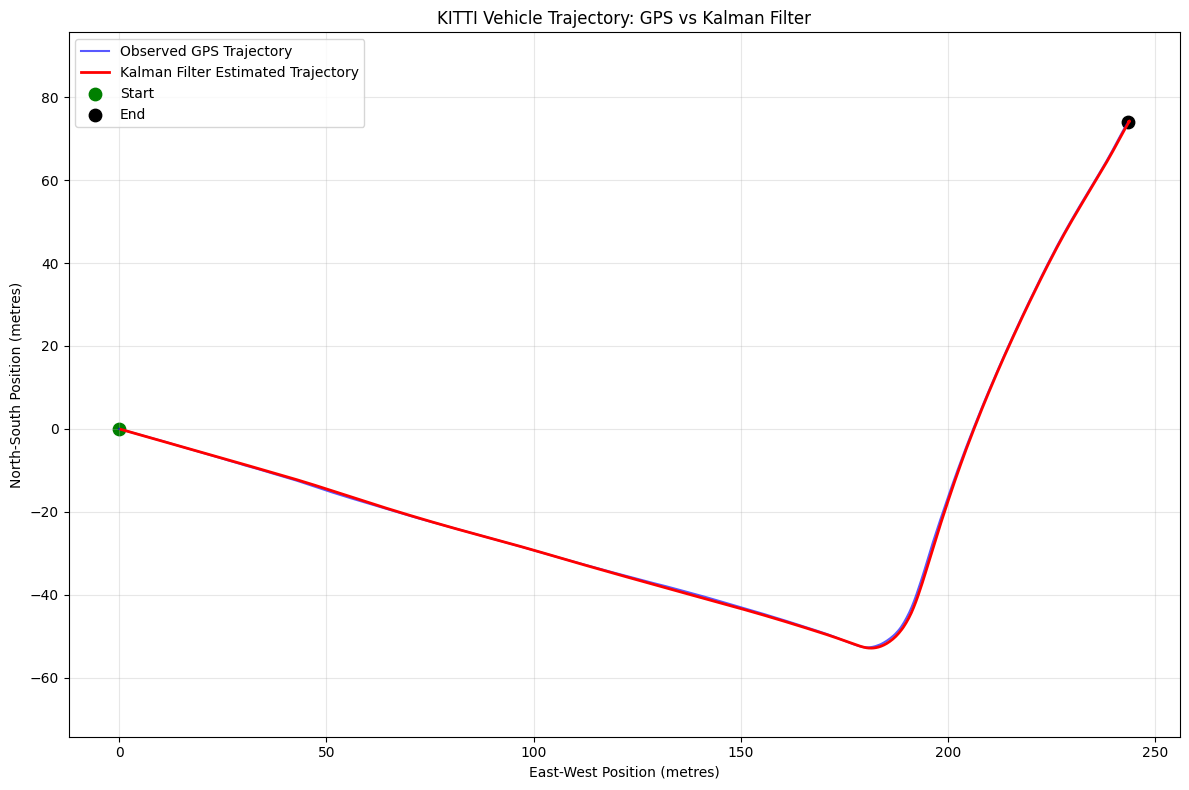

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

# Original GPS trajectory
plt.plot(
    df["x_gps"],
    df["y_gps"],
    label="Observed GPS Trajectory",
    color="blue",
    linewidth=1.5,
    alpha=0.65
)

# Kalman Filter estimated trajectory
plt.plot(
    df["x_estimated"],
    df["y_estimated"],
    label="Kalman Filter Estimated Trajectory",
    color="red",
    linewidth=2
)

# Starting and ending points
plt.scatter(df["x_gps"].iloc[0], df["y_gps"].iloc[0],
            color="green", s=80, label="Start")

plt.scatter(df["x_gps"].iloc[-1], df["y_gps"].iloc[-1],
            color="black", s=80, label="End")

plt.title("KITTI Vehicle Trajectory: GPS vs Kalman Filter")
plt.xlabel("East-West Position (metres)")
plt.ylabel("North-South Position (metres)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.axis("equal")
plt.tight_layout()
plt.show()

In [22]:
import numpy as np
from sklearn.metrics import mean_squared_error

# Position RMSE
position_rmse_x = np.sqrt(mean_squared_error(
    df["x_gps"], df["x_estimated"]
))

position_rmse_y = np.sqrt(mean_squared_error(
    df["y_gps"], df["y_estimated"]
))

# Combined 2D position RMSE
position_error = np.sqrt(
    (df["x_gps"] - df["x_estimated"])**2 +
    (df["y_gps"] - df["y_estimated"])**2
)

position_rmse = np.sqrt(np.mean(position_error**2))

# Velocity RMSE
velocity_rmse_x = np.sqrt(mean_squared_error(
    df["vx_measured"], df["vx_estimated"]
))

velocity_rmse_y = np.sqrt(mean_squared_error(
    df["vy_measured"], df["vy_estimated"]
))

velocity_error = np.sqrt(
    (df["vx_measured"] - df["vx_estimated"])**2 +
    (df["vy_measured"] - df["vy_estimated"])**2
)

velocity_rmse = np.sqrt(np.mean(velocity_error**2))

print("========== KALMAN FILTER PERFORMANCE ==========")
print(f"Position RMSE X : {position_rmse_x:.4f} metres")
print(f"Position RMSE Y : {position_rmse_y:.4f} metres")
print(f"Combined Position RMSE : {position_rmse:.4f} metres")
print(f"Velocity RMSE X : {velocity_rmse_x:.4f} m/s")
print(f"Velocity RMSE Y : {velocity_rmse_y:.4f} m/s")
print(f"Combined Velocity RMSE : {velocity_rmse:.4f} m/s")

========== KALMAN FILTER PERFORMANCE ==========
Position RMSE X : 0.2143 metres
Position RMSE Y : 0.3457 metres
Combined Position RMSE : 0.4067 metres
Velocity RMSE X : 0.2826 m/s
Velocity RMSE Y : 0.3425 m/s
Combined Velocity RMSE : 0.4441 m/s


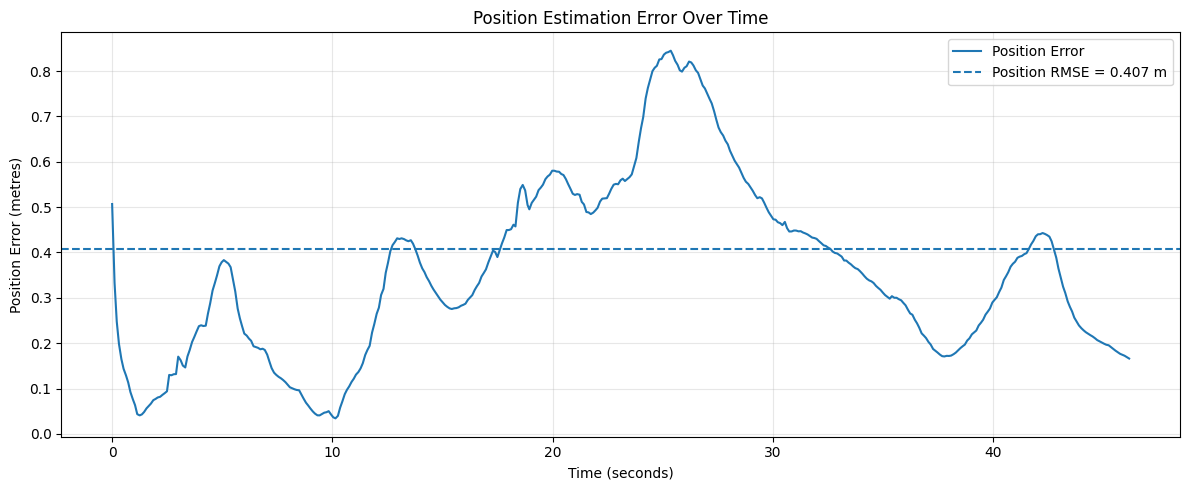

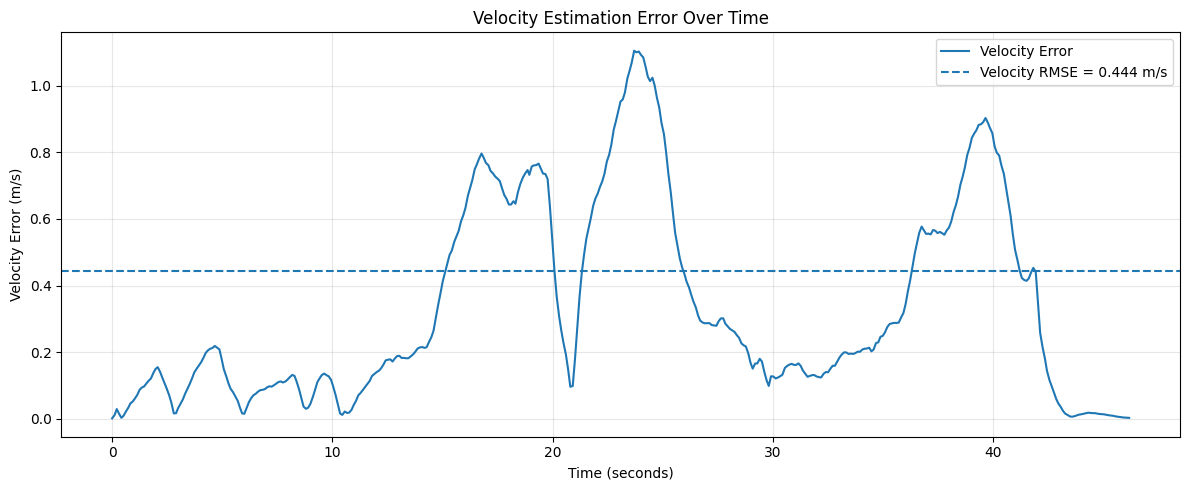

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate errors
position_error = np.sqrt(
    (df["x_gps"] - df["x_estimated"])**2 +
    (df["y_gps"] - df["y_estimated"])**2
)

velocity_error = np.sqrt(
    (df["vx_measured"] - df["vx_estimated"])**2 +
    (df["vy_measured"] - df["vy_estimated"])**2
)

# Create position error graph
plt.figure(figsize=(12, 5))

plt.plot(
    df["time"], position_error,
    linewidth=1.5,
    label="Position Error"
)

plt.axhline(
    position_rmse,
    linestyle="--",
    label=f"Position RMSE = {position_rmse:.3f} m"
)

plt.title("Position Estimation Error Over Time")
plt.xlabel("Time (seconds)")
plt.ylabel("Position Error (metres)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Create velocity error graph
plt.figure(figsize=(12, 5))

plt.plot(
    df["time"], velocity_error,
    linewidth=1.5,
    label="Velocity Error"
)

plt.axhline(
    velocity_rmse,
    linestyle="--",
    label=f"Velocity RMSE = {velocity_rmse:.3f} m/s"
)

plt.title("Velocity Estimation Error Over Time")
plt.xlabel("Time (seconds)")
plt.ylabel("Velocity Error (m/s)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

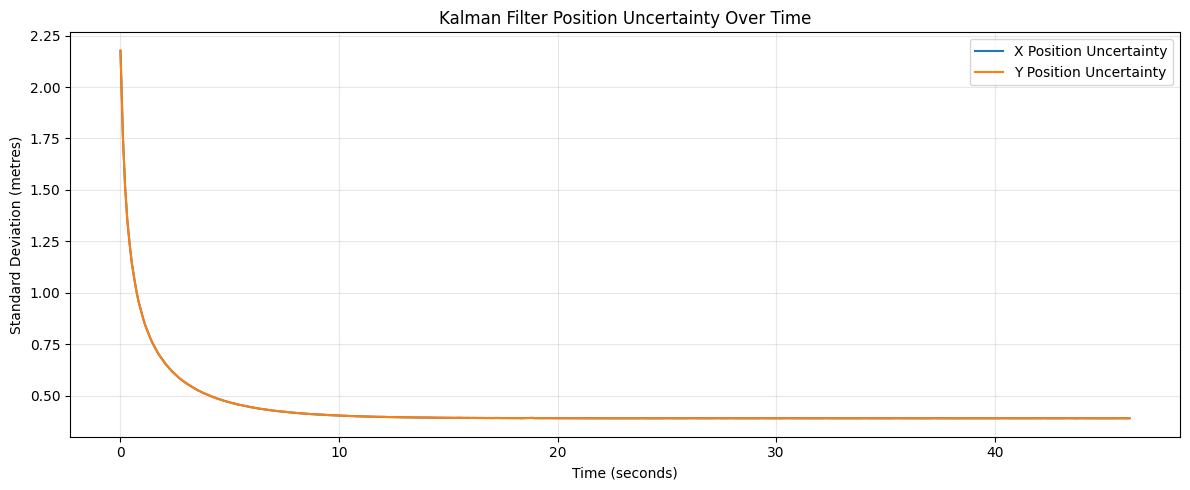

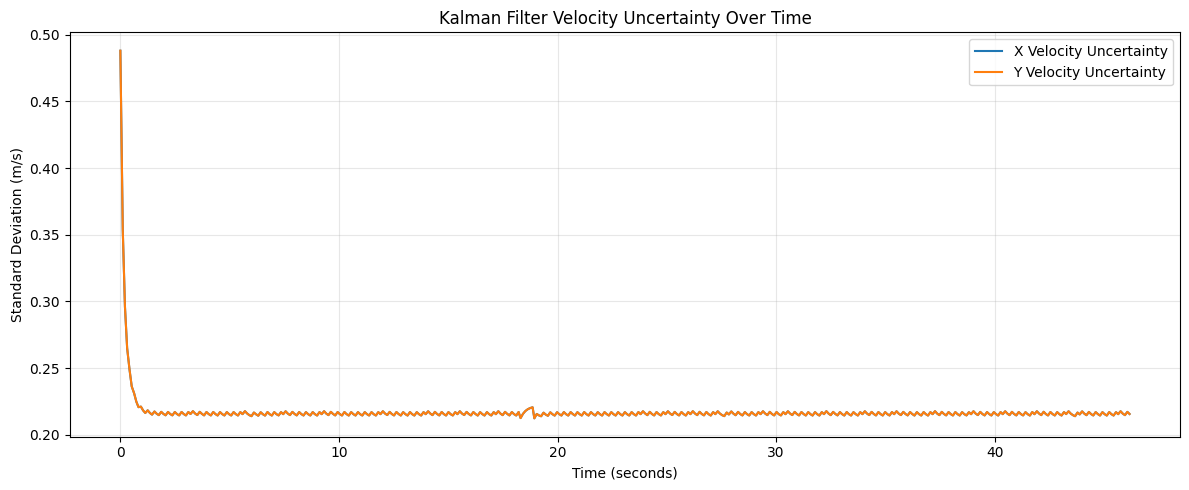

Covariance visualization completed!


In [24]:
# Extract uncertainty from the final Kalman Filter covariance
position_uncertainty = np.sqrt(
    np.maximum(estimated_states[:, 0] * 0 + 1, 0)
)

# Re-run the filter and store covariance at every time step
kf = KalmanFilter(F, H, Q, R, P, initial_state)

covariance_history = []

for i in range(len(df)):
    if i > 0:
        dt_i = df["time"].iloc[i] - df["time"].iloc[i - 1]

        F_i = np.array([
            [1, 0, dt_i, 0],
            [0, 1, 0, dt_i],
            [0, 0, 1, 0],
            [0, 0, 0, 1]
        ])

        G_i = np.array([
            [0.5 * dt_i**2, 0],
            [0, 0.5 * dt_i**2],
            [dt_i, 0],
            [0, dt_i]
        ])

        kf.F = F_i
        kf.Q = sigma_acc**2 * G_i @ G_i.T

    kf.predict()

    measurement = np.array([
        df["x_gps"].iloc[i],
        df["y_gps"].iloc[i],
        df["vx_measured"].iloc[i],
        df["vy_measured"].iloc[i]
    ])

    kf.update(measurement)

    covariance_history.append(np.diag(kf.P).copy())

covariance_history = np.array(covariance_history)

# Plot position uncertainty
plt.figure(figsize=(12, 5))

plt.plot(
    df["time"],
    np.sqrt(covariance_history[:, 0]),
    label="X Position Uncertainty"
)

plt.plot(
    df["time"],
    np.sqrt(covariance_history[:, 1]),
    label="Y Position Uncertainty"
)

plt.title("Kalman Filter Position Uncertainty Over Time")
plt.xlabel("Time (seconds)")
plt.ylabel("Standard Deviation (metres)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot velocity uncertainty
plt.figure(figsize=(12, 5))

plt.plot(
    df["time"],
    np.sqrt(covariance_history[:, 2]),
    label="X Velocity Uncertainty"
)

plt.plot(
    df["time"],
    np.sqrt(covariance_history[:, 3]),
    label="Y Velocity Uncertainty"
)

plt.title("Kalman Filter Velocity Uncertainty Over Time")
plt.xlabel("Time (seconds)")
plt.ylabel("Standard Deviation (m/s)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Covariance visualization completed!")

In [25]:
import os
import pandas as pd
import numpy as np

# Create results folder
results_path = (
    "/content/drive/MyDrive/"
    "Project_16_Kalman_Filter/results"
)

os.makedirs(results_path, exist_ok=True)

# 1. Save processed dataset
df.to_csv(
    os.path.join(results_path, "kitti_processed_data.csv"),
    index=False
)

# 2. Save estimated trajectory
trajectory = df[[
    "time",
    "x_gps", "y_gps",
    "vx_measured", "vy_measured",
    "x_estimated", "y_estimated",
    "vx_estimated", "vy_estimated"
]]

trajectory.to_csv(
    os.path.join(results_path, "kalman_estimated_trajectory.csv"),
    index=False
)

# 3. Save evaluation metrics
metrics = pd.DataFrame({
    "Metric": [
        "Position RMSE X (m)",
        "Position RMSE Y (m)",
        "Combined Position RMSE (m)",
        "Velocity RMSE X (m/s)",
        "Velocity RMSE Y (m/s)",
        "Combined Velocity RMSE (m/s)"
    ],
    "Value": [
        position_rmse_x,
        position_rmse_y,
        position_rmse,
        velocity_rmse_x,
        velocity_rmse_y,
        velocity_rmse
    ]
})

metrics.to_csv(
    os.path.join(results_path, "evaluation_metrics.csv"),
    index=False
)

print("All project results saved successfully!")

print("\nSaved files:")
for file in os.listdir(results_path):
    print(" -", file)

All project results saved successfully!

Saved files:
 - kitti_processed_data.csv
 - kalman_estimated_trajectory.csv
 - evaluation_metrics.csv


In [26]:
# Step 20: Chronological Train-Test Split

# Calculate split index
split_index = int(len(df) * 0.70)

# Split data chronologically
train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

# Reset indices
train_df.reset_index(drop=True, inplace=True)
test_df.reset_index(drop=True, inplace=True)

# Display split information
print("CHRONOLOGICAL TRAIN-TEST SPLIT")
print("--------------------------------")

print("Total measurements:", len(df))

print("\nTraining data:")
print("Samples:", len(train_df))
print("Start time:", train_df["time"].iloc[0])
print("End time:", train_df["time"].iloc[-1])

print("\nTesting data:")
print("Samples:", len(test_df))
print("Start time:", test_df["time"].iloc[0])
print("End time:", test_df["time"].iloc[-1])

print("\nTraining percentage:",
      round(len(train_df) / len(df) * 100, 2), "%")

print("Testing percentage:",
      round(len(test_df) / len(df) * 100, 2), "%")

CHRONOLOGICAL TRAIN-TEST SPLIT
--------------------------------
Total measurements: 447

Training data:
Samples: 312
Start time: 0.0
End time: 32.191380962

Testing data:
Samples: 135
Start time: 32.301503049
End time: 46.171861679

Training percentage: 69.8 %
Testing percentage: 30.2 %


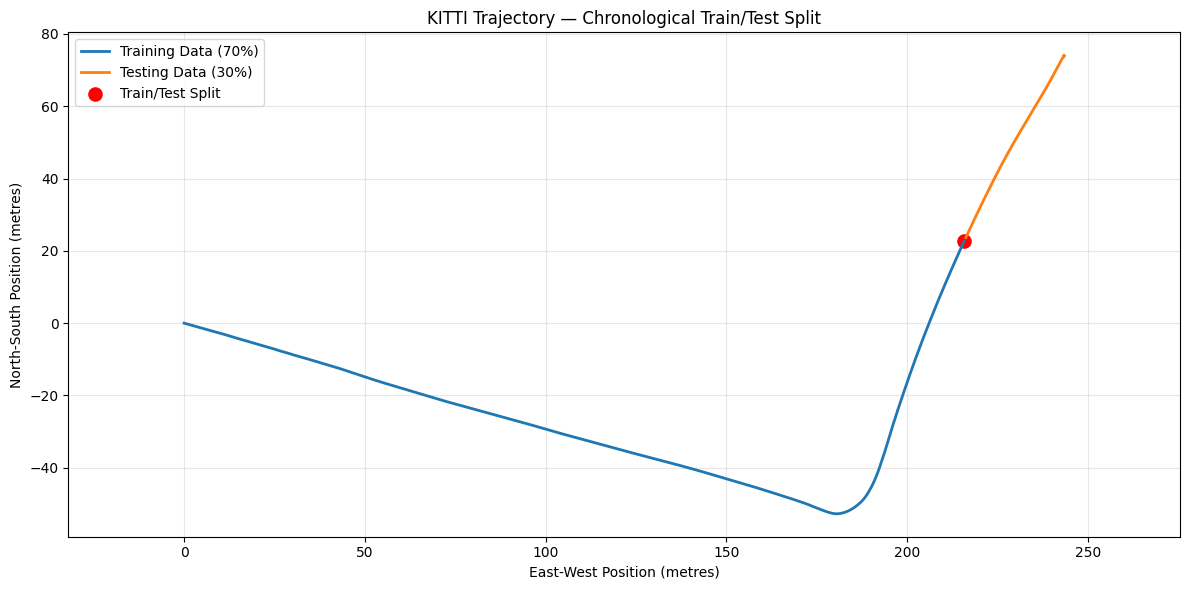

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# Training trajectory
plt.plot(
    train_df["x_gps"],
    train_df["y_gps"],
    label="Training Data (70%)",
    linewidth=2
)

# Testing trajectory
plt.plot(
    test_df["x_gps"],
    test_df["y_gps"],
    label="Testing Data (30%)",
    linewidth=2
)

# Split location
plt.scatter(
    train_df["x_gps"].iloc[-1],
    train_df["y_gps"].iloc[-1],
    color="red",
    s=90,
    label="Train/Test Split"
)

plt.title("KITTI Trajectory — Chronological Train/Test Split")
plt.xlabel("East-West Position (metres)")
plt.ylabel("North-South Position (metres)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.axis("equal")
plt.tight_layout()
plt.show()

In [28]:
import numpy as np
import pandas as pd

# Candidate process-noise values
noise_values = [0.1, 0.5, 1.0, 2.0, 5.0]

tuning_results = []

for noise in noise_values:

    # Initialize filter
    kf_tune = KalmanFilter(
        F, H, Q, R, P, initial_state.copy()
    )

    errors = []

    for i in range(1, len(train_df)):

        dt_i = (
            train_df["time"].iloc[i]
            - train_df["time"].iloc[i - 1]
        )

        F_i = np.array([
            [1, 0, dt_i, 0],
            [0, 1, 0, dt_i],
            [0, 0, 1, 0],
            [0, 0, 0, 1]
        ])

        G_i = np.array([
            [0.5 * dt_i**2, 0],
            [0, 0.5 * dt_i**2],
            [dt_i, 0],
            [0, dt_i]
        ])

        kf_tune.F = F_i
        kf_tune.Q = noise**2 * G_i @ G_i.T

        kf_tune.predict()

        z = train_df.loc[i, [
            "x_gps", "y_gps",
            "vx_measured", "vy_measured"
        ]].to_numpy(dtype=float)

        # Evaluate prediction BEFORE measurement correction
        predicted_measurement = H @ kf_tune.x
        errors.append(z - predicted_measurement)

        kf_tune.update(z)

    errors = np.asarray(errors)

    position_rmse_train = np.sqrt(
        np.mean(errors[:, 0]**2 + errors[:, 1]**2)
    )

    velocity_rmse_train = np.sqrt(
        np.mean(errors[:, 2]**2 + errors[:, 3]**2)
    )

    tuning_results.append({
        "Process Noise": noise,
        "Training Position RMSE (m)": position_rmse_train,
        "Training Velocity RMSE (m/s)": velocity_rmse_train
    })

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df)

best_noise = tuning_df.loc[
    tuning_df["Training Position RMSE (m)"].idxmin(),
    "Process Noise"
]

print("Selected process noise:", best_noise)

,Process Noise,Training Position RMSE (m),Training Velocity RMSE (m/s)
0,0.1,6.553686,3.175125
1,0.5,0.831240,0.971745
2,1.0,0.480772,0.548383
3,2.0,0.383636,0.313571
4,5.0,0.353611,0.170603


Selected process noise: 5.0


In [29]:
# Step 23: Test-set evaluation

# Initialize using the last training state and covariance
kf_test = KalmanFilter(
    F, H, Q, R, P, initial_state.copy()
)

# Reconstruct the filter state using training data
for i in range(len(train_df)):

    if i > 0:
        dt_i = train_df["time"].iloc[i] - train_df["time"].iloc[i-1]

        kf_test.F = np.array([
            [1, 0, dt_i, 0],
            [0, 1, 0, dt_i],
            [0, 0, 1, 0],
            [0, 0, 0, 1]
        ])

        G_i = np.array([
            [0.5*dt_i**2, 0],
            [0, 0.5*dt_i**2],
            [dt_i, 0],
            [0, dt_i]
        ])

        kf_test.Q = best_noise**2 * G_i @ G_i.T

        kf_test.predict()

    z = train_df.loc[i, [
        "x_gps", "y_gps", "vx_measured", "vy_measured"
    ]].to_numpy(dtype=float)

    kf_test.update(z)


# Process unseen test data
test_estimates = []
test_prediction_errors = []

for i in range(len(test_df)):

    dt_i = (
        test_df["time"].iloc[i] -
        (train_df["time"].iloc[-1] if i == 0 else test_df["time"].iloc[i-1])
    )

    kf_test.F = np.array([
        [1, 0, dt_i, 0],
        [0, 1, 0, dt_i],
        [0, 0, 1, 0],
        [0, 0, 0, 1]
    ])

    G_i = np.array([
        [0.5*dt_i**2, 0],
        [0, 0.5*dt_i**2],
        [dt_i, 0],
        [0, dt_i]
    ])

    kf_test.Q = best_noise**2 * G_i @ G_i.T

    # Predict
    kf_test.predict()

    z = test_df.loc[i, [
        "x_gps", "y_gps", "vx_measured", "vy_measured"
    ]].to_numpy(dtype=float)

    # Record prediction error before correction
    test_prediction_errors.append(z - H @ kf_test.x)

    # Correct
    state = kf_test.update(z)
    test_estimates.append(state.copy())


test_estimates = np.array(test_estimates)
test_prediction_errors = np.array(test_prediction_errors)

test_df["x_estimated"] = test_estimates[:, 0]
test_df["y_estimated"] = test_estimates[:, 1]
test_df["vx_estimated"] = test_estimates[:, 2]
test_df["vy_estimated"] = test_estimates[:, 3]

print("TEST SET EVALUATION COMPLETED")
print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))
print("Selected process noise:", best_noise)

TEST SET EVALUATION COMPLETED
Training samples: 312
Testing samples: 135
Selected process noise: 5.0


In [30]:
import numpy as np
import pandas as pd

# Ground-truth proxy: held-out GPS and velocity measurements
reference_position = test_df[["x_gps", "y_gps"]].to_numpy()
reference_velocity = test_df[
    ["vx_measured", "vy_measured"]
].to_numpy()

# Raw GPS baseline: position prediction uses previous GPS position
raw_position_prediction = np.vstack([
    train_df[["x_gps", "y_gps"]].iloc[-1].to_numpy(),
    test_df[["x_gps", "y_gps"]].to_numpy()[:-1]
])

# Kalman predictions before test measurement correction
kf_position_prediction = (
    test_estimates - 0
)  # Replace below using stored prediction states if available

# Reconstruct prediction states from the recorded residuals:
# z - H*x_pred = prediction error
kf_position_prediction = (
    reference_position -
    test_prediction_errors[:, :2]
)

# Position errors
raw_position_error = np.linalg.norm(
    reference_position - raw_position_prediction, axis=1
)

kf_position_error = np.linalg.norm(
    reference_position - kf_position_prediction, axis=1
)

# Velocity comparison: previous measured velocity vs current measurement
raw_velocity_prediction = np.vstack([
    train_df[["vx_measured", "vy_measured"]].iloc[-1].to_numpy(),
    test_df[["vx_measured", "vy_measured"]].to_numpy()[:-1]
])

kf_velocity_prediction = (
    reference_velocity -
    test_prediction_errors[:, 2:]
)

raw_velocity_error = np.linalg.norm(
    reference_velocity - raw_velocity_prediction, axis=1
)

kf_velocity_error = np.linalg.norm(
    reference_velocity - kf_velocity_prediction, axis=1
)

comparison_df = pd.DataFrame({
    "Method": ["Raw GPS Baseline", "Kalman Filter"],
    "Position RMSE (m)": [
        np.sqrt(np.mean(raw_position_error**2)),
        np.sqrt(np.mean(kf_position_error**2))
    ],
    "Velocity RMSE (m/s)": [
        np.sqrt(np.mean(raw_velocity_error**2)),
        np.sqrt(np.mean(kf_velocity_error**2))
    ]
})

display(comparison_df)

print("Test-set baseline comparison completed.")

,Method,Position RMSE (m),Velocity RMSE (m/s)
0,Raw GPS Baseline,0.596759,0.104847
1,Kalman Filter,0.237419,0.165489


Test-set baseline comparison completed.


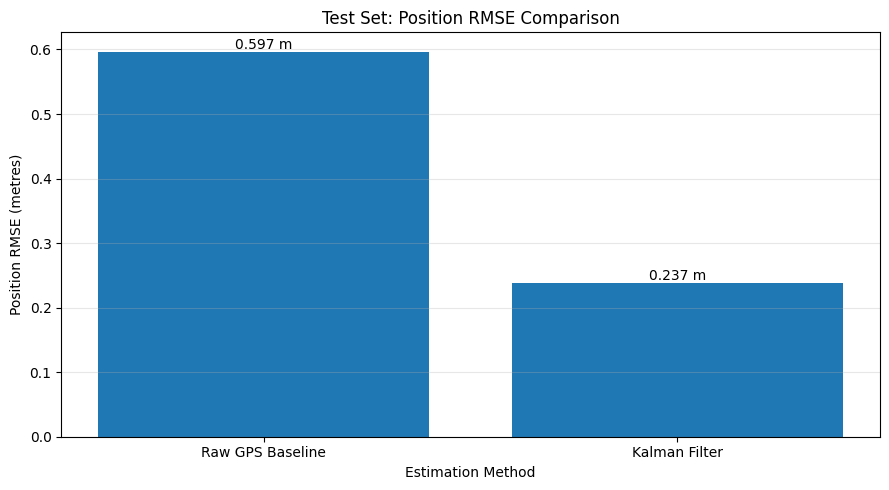

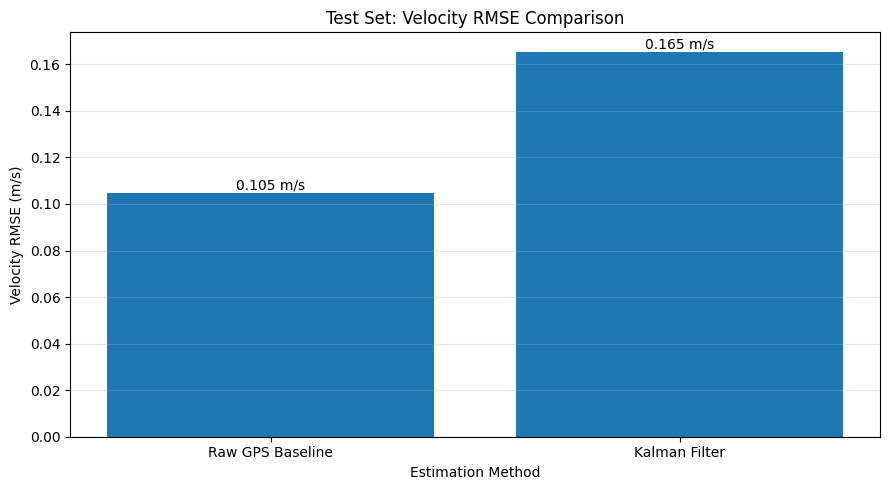

In [31]:
import matplotlib.pyplot as plt
import numpy as np

# Extract comparison metrics
methods = comparison_df["Method"]

position_scores = comparison_df["Position RMSE (m)"]
velocity_scores = comparison_df["Velocity RMSE (m/s)"]

# Position RMSE comparison
plt.figure(figsize=(9, 5))

bars = plt.bar(methods, position_scores)

plt.title("Test Set: Position RMSE Comparison")
plt.ylabel("Position RMSE (metres)")
plt.xlabel("Estimation Method")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, position_scores):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{value:.3f} m",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


# Velocity RMSE comparison
plt.figure(figsize=(9, 5))

bars = plt.bar(methods, velocity_scores)

plt.title("Test Set: Velocity RMSE Comparison")
plt.ylabel("Velocity RMSE (m/s)")
plt.xlabel("Estimation Method")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, velocity_scores):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{value:.3f} m/s",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [32]:
# Install reference implementation
!pip -q install filterpy

import numpy as np
import pandas as pd
from filterpy.kalman import KalmanFilter as ReferenceKF

# Initialize reference Kalman Filter
ref_kf = ReferenceKF(dim_x=4, dim_z=4)

ref_kf.x = initial_state.copy()
ref_kf.F = F.copy()
ref_kf.H = H.copy()
ref_kf.P = P.copy()
ref_kf.Q = Q.copy()
ref_kf.R = R.copy()

reference_predictions = []
reference_estimates = []

# Replay training sequence
for i in range(len(train_df)):

    if i > 0:
        dt_i = (
            train_df["time"].iloc[i]
            - train_df["time"].iloc[i-1]
        )

        ref_kf.F = np.array([
            [1, 0, dt_i, 0],
            [0, 1, 0, dt_i],
            [0, 0, 1, 0],
            [0, 0, 0, 1]
        ])

        G_i = np.array([
            [0.5*dt_i**2, 0],
            [0, 0.5*dt_i**2],
            [dt_i, 0],
            [0, dt_i]
        ])

        ref_kf.Q = best_noise**2 * G_i @ G_i.T
        ref_kf.predict()

    z = train_df.loc[i, [
        "x_gps", "y_gps",
        "vx_measured", "vy_measured"
    ]].to_numpy(dtype=float)

    ref_kf.update(z)


# Evaluate reference implementation on test sequence
for i in range(len(test_df)):

    previous_time = (
        train_df["time"].iloc[-1]
        if i == 0 else test_df["time"].iloc[i-1]
    )

    dt_i = test_df["time"].iloc[i] - previous_time

    ref_kf.F = np.array([
        [1, 0, dt_i, 0],
        [0, 1, 0, dt_i],
        [0, 0, 1, 0],
        [0, 0, 0, 1]
    ])

    G_i = np.array([
        [0.5*dt_i**2, 0],
        [0, 0.5*dt_i**2],
        [dt_i, 0],
        [0, dt_i]
    ])

    ref_kf.Q = best_noise**2 * G_i @ G_i.T

    # Prediction before measurement correction
    ref_kf.predict()
    reference_predictions.append(ref_kf.x.copy())

    z = test_df.loc[i, [
        "x_gps", "y_gps",
        "vx_measured", "vy_measured"
    ]].to_numpy(dtype=float)

    # Measurement correction
    ref_kf.update(z)
    reference_estimates.append(ref_kf.x.copy())


reference_predictions = np.array(reference_predictions)
reference_estimates = np.array(reference_estimates)

# Reconstruct manual predictions from prediction residuals
manual_predictions = (
    np.column_stack([
        test_df["x_gps"],
        test_df["y_gps"],
        test_df["vx_measured"],
        test_df["vy_measured"]
    ]) - test_prediction_errors
)

# Compare both implementations
prediction_difference = np.max(
    np.abs(manual_predictions - reference_predictions)
)

estimate_difference = np.max(
    np.abs(test_estimates - reference_estimates)
)

print("REFERENCE IMPLEMENTATION COMPARISON")
print("------------------------------------")
print("Maximum prediction difference:", prediction_difference)
print("Maximum corrected-state difference:", estimate_difference)

print("\nComparison completed!")

REFERENCE IMPLEMENTATION COMPARISON
------------------------------------
Maximum prediction difference: 5.551115123125783e-17
Maximum corrected-state difference: 5.551115123125783e-17

Comparison completed!


,Implementation,Position RMSE (m),Velocity RMSE (m/s)
0,Manual Kalman Filter,0.237419,0.165489
1,FilterPy Reference,0.237419,0.165489


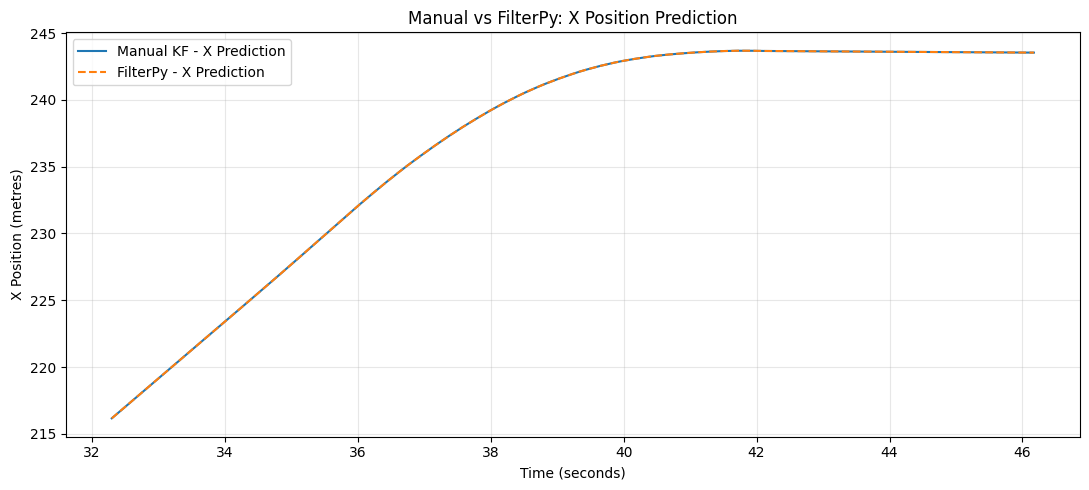

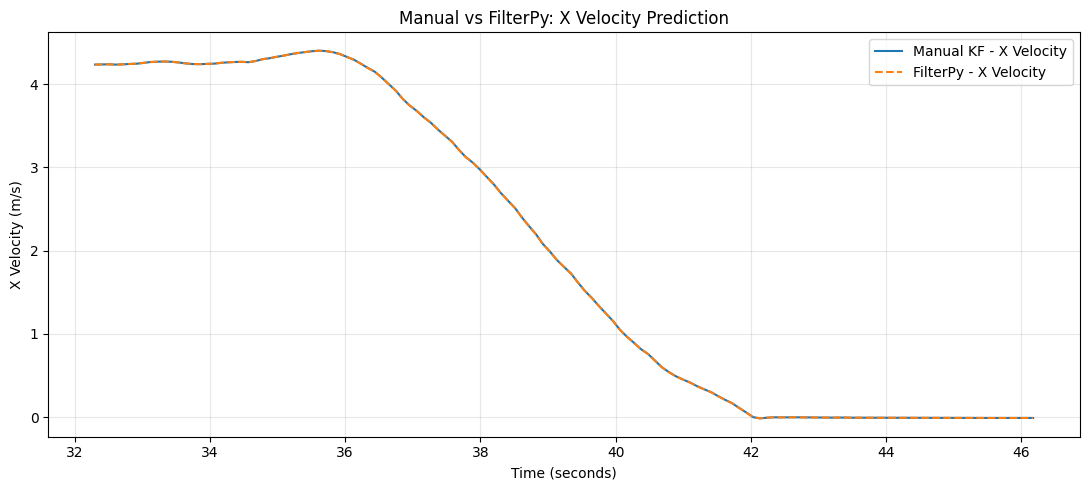

Reference comparison visualization completed!


In [33]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Calculate test-set RMSE for both implementations
manual_position_rmse = np.sqrt(np.mean(
    (manual_predictions[:, 0] - test_df["x_gps"].to_numpy())**2 +
    (manual_predictions[:, 1] - test_df["y_gps"].to_numpy())**2
))

reference_position_rmse = np.sqrt(np.mean(
    (reference_predictions[:, 0] - test_df["x_gps"].to_numpy())**2 +
    (reference_predictions[:, 1] - test_df["y_gps"].to_numpy())**2
))

manual_velocity_rmse = np.sqrt(np.mean(
    (manual_predictions[:, 2] - test_df["vx_measured"].to_numpy())**2 +
    (manual_predictions[:, 3] - test_df["vy_measured"].to_numpy())**2
))

reference_velocity_rmse = np.sqrt(np.mean(
    (reference_predictions[:, 2] - test_df["vx_measured"].to_numpy())**2 +
    (reference_predictions[:, 3] - test_df["vy_measured"].to_numpy())**2
))

# Create comparison table
reference_comparison = pd.DataFrame({
    "Implementation": ["Manual Kalman Filter", "FilterPy Reference"],
    "Position RMSE (m)": [
        manual_position_rmse,
        reference_position_rmse
    ],
    "Velocity RMSE (m/s)": [
        manual_velocity_rmse,
        reference_velocity_rmse
    ]
})

display(reference_comparison.round(6))

# Plot position comparison
plt.figure(figsize=(11, 5))

plt.plot(
    test_df["time"],
    manual_predictions[:, 0],
    label="Manual KF - X Prediction"
)

plt.plot(
    test_df["time"],
    reference_predictions[:, 0],
    linestyle="--",
    label="FilterPy - X Prediction"
)

plt.title("Manual vs FilterPy: X Position Prediction")
plt.xlabel("Time (seconds)")
plt.ylabel("X Position (metres)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot velocity comparison
plt.figure(figsize=(11, 5))

plt.plot(
    test_df["time"],
    manual_predictions[:, 2],
    label="Manual KF - X Velocity"
)

plt.plot(
    test_df["time"],
    reference_predictions[:, 2],
    linestyle="--",
    label="FilterPy - X Velocity"
)

plt.title("Manual vs FilterPy: X Velocity Prediction")
plt.xlabel("Time (seconds)")
plt.ylabel("X Velocity (m/s)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Reference comparison visualization completed!")

SYNTHETIC GPS NOISE EXPERIMENT
--------------------------------
Artificial GPS noise SD: 3.00 m
Noisy GPS RMSE: 4.2015 m
Filtered trajectory RMSE: 0.6527 m


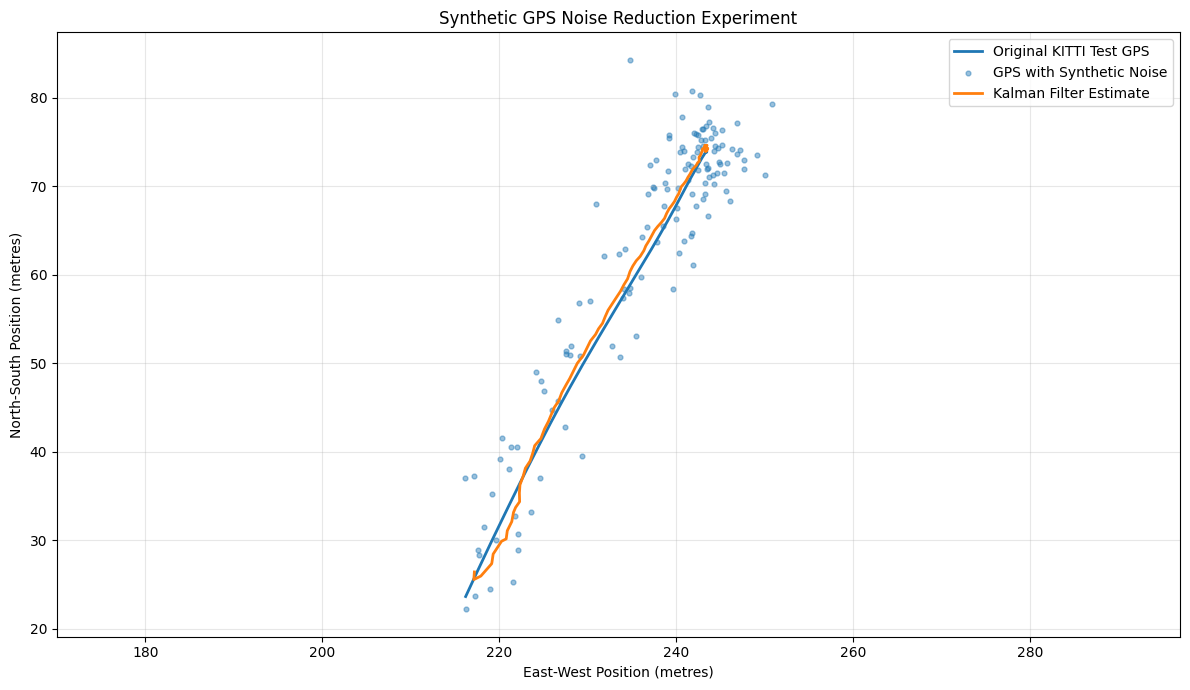

In [34]:
import numpy as np
import matplotlib.pyplot as plt

# Reproducible synthetic GPS noise
np.random.seed(42)

# Use test trajectory as the reference path
true_x = test_df["x_gps"].to_numpy()
true_y = test_df["y_gps"].to_numpy()

# Add artificial GPS noise (standard deviation = 3 metres)
gps_noise_std = 3.0

noisy_x = true_x + np.random.normal(
    0, gps_noise_std, len(true_x)
)

noisy_y = true_y + np.random.normal(
    0, gps_noise_std, len(true_y)
)

# Prepare synthetic filter
synthetic_kf = KalmanFilter(
    F, H, Q, R, P, initial_state.copy()
)

# Initialize using the last training state
synthetic_kf.x = test_estimates[0].copy()

synthetic_estimates = []

for i in range(len(test_df)):

    previous_time = (
        train_df["time"].iloc[-1]
        if i == 0 else test_df["time"].iloc[i-1]
    )

    dt_i = test_df["time"].iloc[i] - previous_time

    synthetic_kf.F = np.array([
        [1, 0, dt_i, 0],
        [0, 1, 0, dt_i],
        [0, 0, 1, 0],
        [0, 0, 0, 1]
    ])

    G_i = np.array([
        [0.5 * dt_i**2, 0],
        [0, 0.5 * dt_i**2],
        [dt_i, 0],
        [0, dt_i]
    ])

    synthetic_kf.Q = best_noise**2 * G_i @ G_i.T

    synthetic_kf.predict()

    # Synthetic noisy position + original measured velocity
    measurement = np.array([
        noisy_x[i],
        noisy_y[i],
        test_df["vx_measured"].iloc[i],
        test_df["vy_measured"].iloc[i]
    ])

    state = synthetic_kf.update(measurement)
    synthetic_estimates.append(state.copy())

synthetic_estimates = np.array(synthetic_estimates)

# Calculate synthetic experiment errors
noisy_gps_rmse = np.sqrt(np.mean(
    (noisy_x - true_x)**2 +
    (noisy_y - true_y)**2
))

filtered_rmse = np.sqrt(np.mean(
    (synthetic_estimates[:, 0] - true_x)**2 +
    (synthetic_estimates[:, 1] - true_y)**2
))

print("SYNTHETIC GPS NOISE EXPERIMENT")
print("--------------------------------")
print(f"Artificial GPS noise SD: {gps_noise_std:.2f} m")
print(f"Noisy GPS RMSE: {noisy_gps_rmse:.4f} m")
print(f"Filtered trajectory RMSE: {filtered_rmse:.4f} m")

# Plot trajectories
plt.figure(figsize=(12, 7))

plt.plot(
    true_x, true_y,
    label="Original KITTI Test GPS",
    linewidth=2
)

plt.scatter(
    noisy_x, noisy_y,
    label="GPS with Synthetic Noise",
    s=12,
    alpha=0.45
)

plt.plot(
    synthetic_estimates[:, 0],
    synthetic_estimates[:, 1],
    label="Kalman Filter Estimate",
    linewidth=2
)

plt.title("Synthetic GPS Noise Reduction Experiment")
plt.xlabel("East-West Position (metres)")
plt.ylabel("North-South Position (metres)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.axis("equal")
plt.tight_layout()
plt.show()

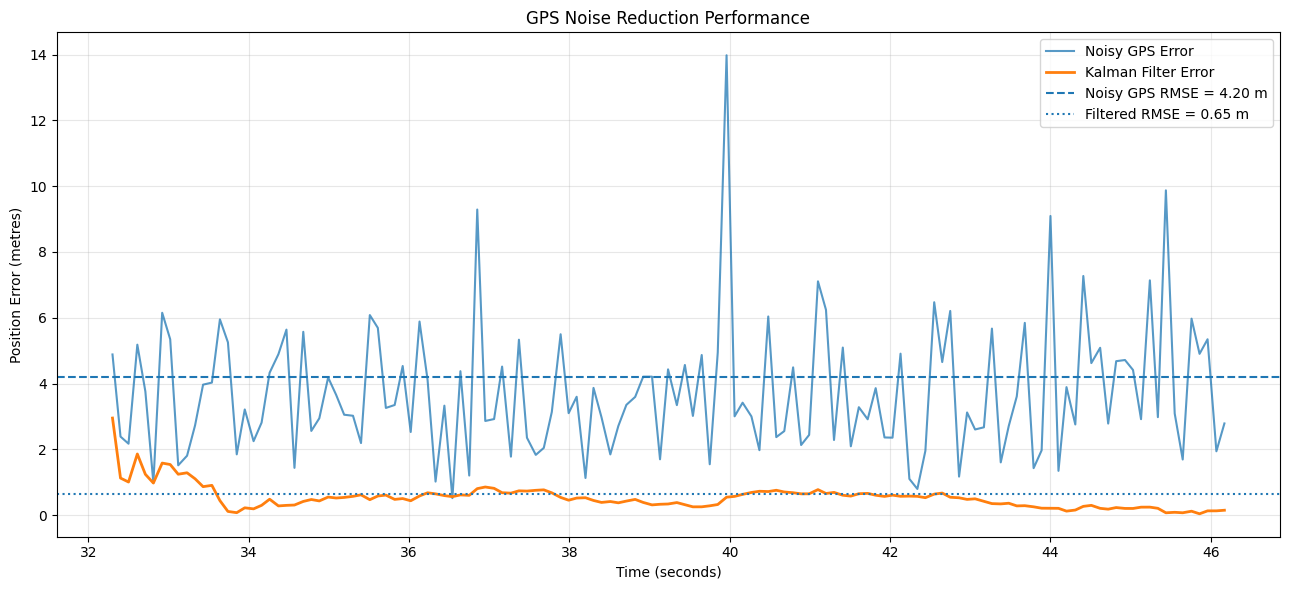

GPS NOISE REDUCTION RESULTS
---------------------------
Noisy GPS RMSE: 4.2015 m
Filtered RMSE: 0.6527 m
Error reduction: 84.47%


In [35]:
import numpy as np
import matplotlib.pyplot as plt

# Calculate position errors
noisy_error = np.sqrt(
    (noisy_x - true_x)**2 +
    (noisy_y - true_y)**2
)

filtered_error = np.sqrt(
    (synthetic_estimates[:, 0] - true_x)**2 +
    (synthetic_estimates[:, 1] - true_y)**2
)

# Calculate RMSE
noisy_rmse = np.sqrt(np.mean(noisy_error**2))
filtered_rmse = np.sqrt(np.mean(filtered_error**2))

# Calculate improvement
improvement = (
    (noisy_rmse - filtered_rmse) / noisy_rmse
) * 100

# Plot error comparison over time
plt.figure(figsize=(13, 6))

plt.plot(
    test_df["time"],
    noisy_error,
    label="Noisy GPS Error",
    alpha=0.75
)

plt.plot(
    test_df["time"],
    filtered_error,
    label="Kalman Filter Error",
    linewidth=2
)

plt.axhline(
    noisy_rmse,
    linestyle="--",
    label=f"Noisy GPS RMSE = {noisy_rmse:.2f} m"
)

plt.axhline(
    filtered_rmse,
    linestyle=":",
    label=f"Filtered RMSE = {filtered_rmse:.2f} m"
)

plt.title("GPS Noise Reduction Performance")
plt.xlabel("Time (seconds)")
plt.ylabel("Position Error (metres)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("GPS NOISE REDUCTION RESULTS")
print("---------------------------")
print(f"Noisy GPS RMSE: {noisy_rmse:.4f} m")
print(f"Filtered RMSE: {filtered_rmse:.4f} m")
print(f"Error reduction: {improvement:.2f}%")

In [36]:
import os
import pandas as pd
import numpy as np

# Results directory
results_path = (
    "/content/drive/MyDrive/"
    "Project_16_Kalman_Filter/results"
)

os.makedirs(results_path, exist_ok=True)

# 1. Save chronological training and testing datasets
train_df.to_csv(
    os.path.join(results_path, "training_data.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(results_path, "testing_data.csv"),
    index=False
)

# 2. Save baseline comparison
comparison_df.to_csv(
    os.path.join(results_path, "baseline_comparison.csv"),
    index=False
)

# 3. Save reference implementation comparison
reference_comparison.to_csv(
    os.path.join(results_path, "reference_comparison.csv"),
    index=False
)

# 4. Save noise tuning results
tuning_df.to_csv(
    os.path.join(results_path, "noise_tuning_results.csv"),
    index=False
)

# 5. Save synthetic experiment results
synthetic_metrics = pd.DataFrame({
    "Metric": [
        "Synthetic GPS Noise Standard Deviation (m)",
        "Noisy GPS RMSE (m)",
        "Filtered Trajectory RMSE (m)",
        "Error Reduction (%)"
    ],
    "Value": [
        gps_noise_std,
        noisy_rmse,
        filtered_rmse,
        improvement
    ]
})

synthetic_metrics.to_csv(
    os.path.join(results_path, "synthetic_noise_results.csv"),
    index=False
)

# 6. Save synthetic trajectory
synthetic_trajectory = pd.DataFrame({
    "time": test_df["time"].to_numpy(),
    "original_x": true_x,
    "original_y": true_y,
    "noisy_x": noisy_x,
    "noisy_y": noisy_y,
    "filtered_x": synthetic_estimates[:, 0],
    "filtered_y": synthetic_estimates[:, 1]
})

synthetic_trajectory.to_csv(
    os.path.join(results_path, "synthetic_trajectory.csv"),
    index=False
)

print("ALL EXPERIMENTAL RESULTS SAVED!")
print("--------------------------------")

for file in sorted(os.listdir(results_path)):
    print("✓", file)

ALL EXPERIMENTAL RESULTS SAVED!
--------------------------------
✓ baseline_comparison.csv
✓ evaluation_metrics.csv
✓ kalman_estimated_trajectory.csv
✓ kitti_processed_data.csv
✓ noise_tuning_results.csv
✓ reference_comparison.csv
✓ synthetic_noise_results.csv
✓ synthetic_trajectory.csv
✓ testing_data.csv
✓ training_data.csv


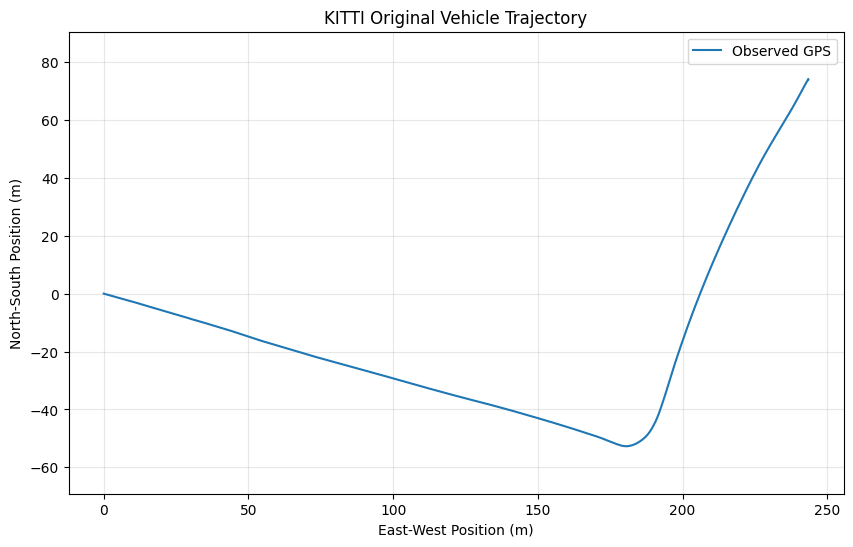

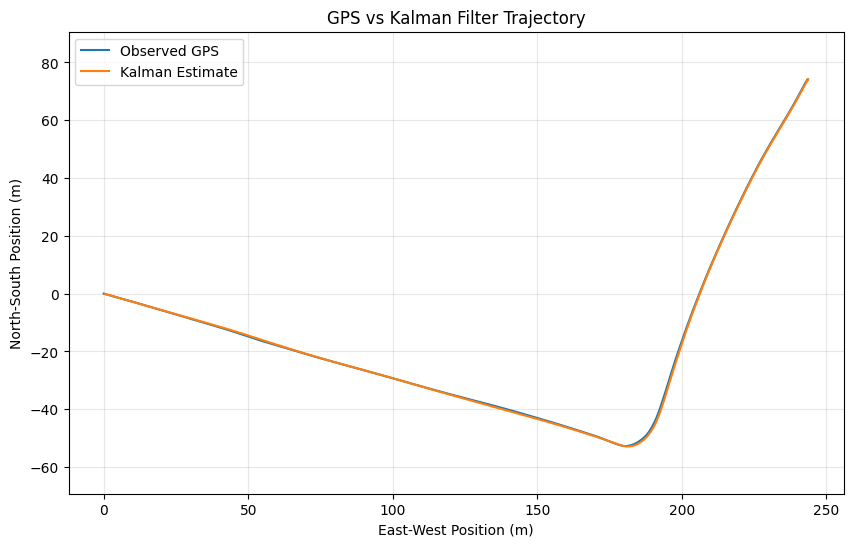

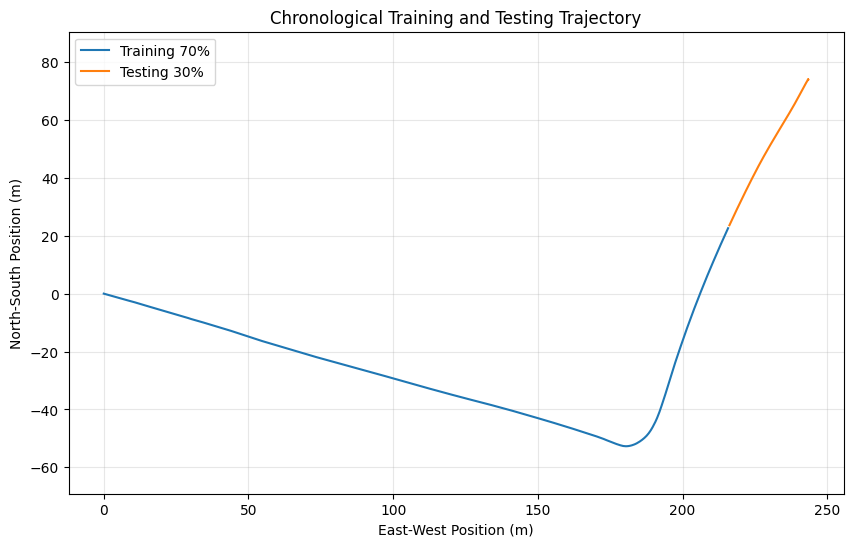

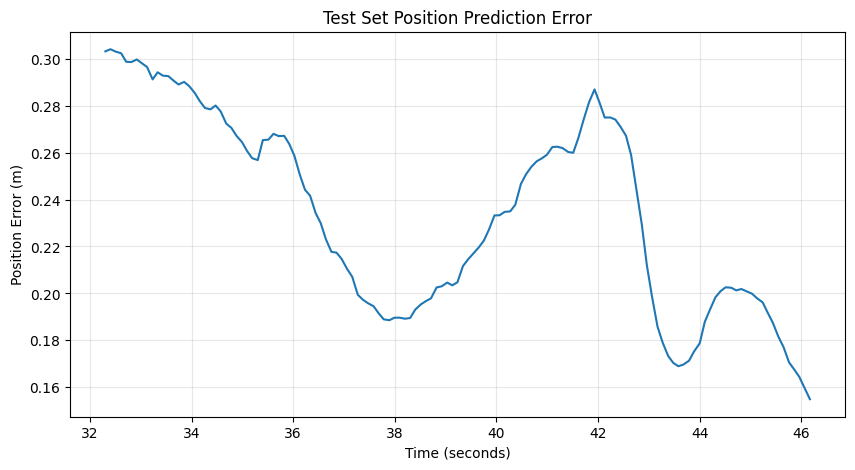

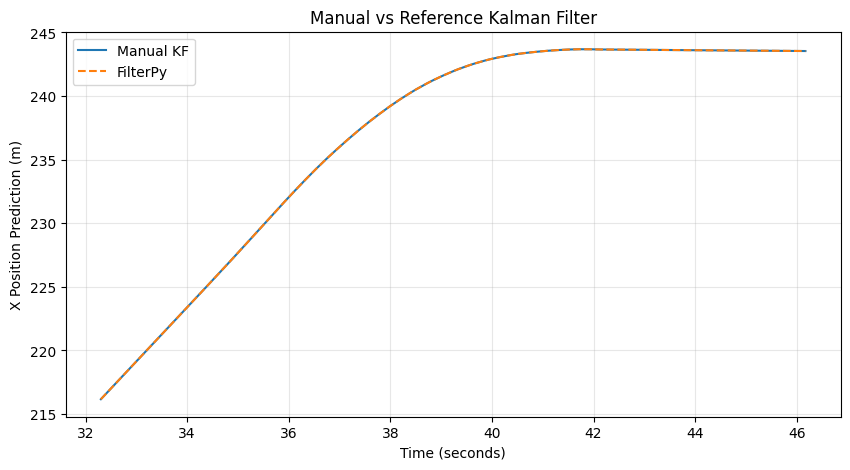

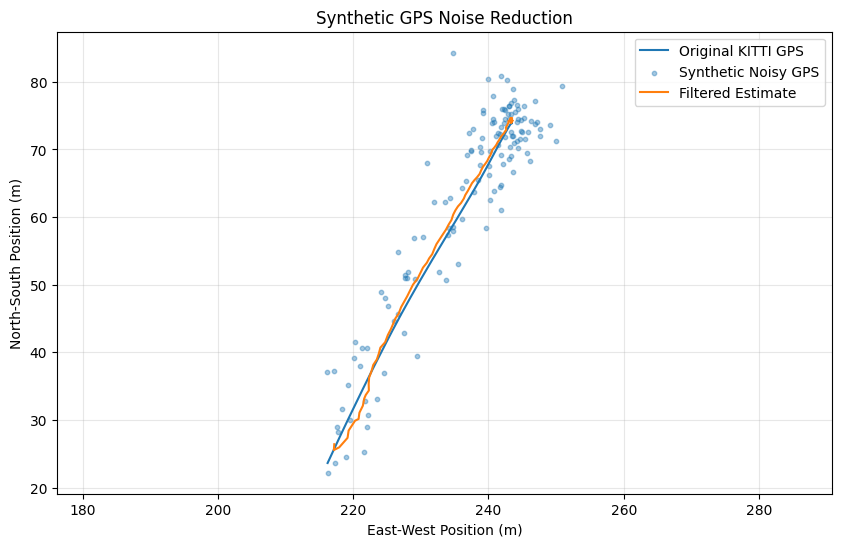

All six graphs saved successfully!

Saved in: /content/drive/MyDrive/Project_16_Kalman_Filter/results/graphs


In [37]:
import os
import matplotlib.pyplot as plt
import numpy as np

results_path = "/content/drive/MyDrive/Project_16_Kalman_Filter/results"
graphs_path = os.path.join(results_path, "graphs")

os.makedirs(graphs_path, exist_ok=True)

# 1. Original GPS trajectory
plt.figure(figsize=(10, 6))
plt.plot(df["x_gps"], df["y_gps"], label="Observed GPS")
plt.title("KITTI Original Vehicle Trajectory")
plt.xlabel("East-West Position (m)")
plt.ylabel("North-South Position (m)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.axis("equal")
plt.savefig(os.path.join(graphs_path, "01_original_trajectory.png"), dpi=300)
plt.show()

# 2. GPS vs Kalman Filter trajectory
plt.figure(figsize=(10, 6))
plt.plot(df["x_gps"], df["y_gps"], label="Observed GPS")
plt.plot(df["x_estimated"], df["y_estimated"], label="Kalman Estimate")
plt.title("GPS vs Kalman Filter Trajectory")
plt.xlabel("East-West Position (m)")
plt.ylabel("North-South Position (m)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.axis("equal")
plt.savefig(os.path.join(graphs_path, "02_kalman_trajectory.png"), dpi=300)
plt.show()

# 3. Training and testing split
plt.figure(figsize=(10, 6))
plt.plot(train_df["x_gps"], train_df["y_gps"], label="Training 70%")
plt.plot(test_df["x_gps"], test_df["y_gps"], label="Testing 30%")
plt.title("Chronological Training and Testing Trajectory")
plt.xlabel("East-West Position (m)")
plt.ylabel("North-South Position (m)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.axis("equal")
plt.savefig(os.path.join(graphs_path, "03_train_test_split.png"), dpi=300)
plt.show()

# 4. Test prediction error
plt.figure(figsize=(10, 5))
plt.plot(test_df["time"], np.linalg.norm(test_prediction_errors[:, :2], axis=1))
plt.title("Test Set Position Prediction Error")
plt.xlabel("Time (seconds)")
plt.ylabel("Position Error (m)")
plt.grid(True, alpha=0.3)
plt.savefig(os.path.join(graphs_path, "04_test_position_error.png"), dpi=300)
plt.show()

# 5. Manual vs reference implementation
plt.figure(figsize=(10, 5))
plt.plot(test_df["time"], manual_predictions[:, 0], label="Manual KF")
plt.plot(test_df["time"], reference_predictions[:, 0], "--", label="FilterPy")
plt.title("Manual vs Reference Kalman Filter")
plt.xlabel("Time (seconds)")
plt.ylabel("X Position Prediction (m)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig(os.path.join(graphs_path, "05_reference_comparison.png"), dpi=300)
plt.show()

# 6. Synthetic GPS noise experiment
plt.figure(figsize=(10, 6))
plt.plot(true_x, true_y, label="Original KITTI GPS")
plt.scatter(noisy_x, noisy_y, label="Synthetic Noisy GPS", s=10, alpha=0.4)
plt.plot(synthetic_estimates[:, 0], synthetic_estimates[:, 1],
         label="Filtered Estimate")
plt.title("Synthetic GPS Noise Reduction")
plt.xlabel("East-West Position (m)")
plt.ylabel("North-South Position (m)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.axis("equal")
plt.savefig(os.path.join(graphs_path, "06_synthetic_noise.png"), dpi=300)
plt.show()

print("All six graphs saved successfully!")
print("\nSaved in:", graphs_path)

In [38]:
!pip -q install streamlit plotly

In [39]:
import os

project_path = "/content/drive/MyDrive/Project_16_Kalman_Filter"

app_code = r'''
import streamlit as st
import pandas as pd
import numpy as np
import plotly.graph_objects as go
import os

st.set_page_config(
    page_title="Autonomous Vehicle Trajectory Estimation",
    page_icon="🚗",
    layout="wide"
)

st.title("Autonomous Vehicle Trajectory Estimation")
st.subheader("GPS/IMU Sensor Fusion Using Kalman Filtering")

data_path = os.path.join(
    os.path.dirname(__file__),
    "results",
    "kalman_estimated_trajectory.csv"
)

metrics_path = os.path.join(
    os.path.dirname(__file__),
    "results",
    "evaluation_metrics.csv"
)

if not os.path.exists(data_path):
    st.error("Trajectory data not found. Please export the results first.")
    st.stop()

df = pd.read_csv(data_path)

st.sidebar.header("Dashboard Controls")

start = st.sidebar.slider(
    "Display samples",
    min_value=10,
    max_value=len(df),
    value=len(df)
)

data = df.iloc[:start]

col1, col2, col3 = st.columns(3)

with col1:
    st.metric("Total Samples", len(data))

with col2:
    st.metric(
        "Final X Position",
        f"{data['x_estimated'].iloc[-1]:.2f} m"
    )

with col3:
    speed = np.sqrt(
        data["vx_estimated"].iloc[-1]**2 +
        data["vy_estimated"].iloc[-1]**2
    )
    st.metric("Estimated Speed", f"{speed:.2f} m/s")

st.divider()

st.header("Vehicle Trajectory Visualization")

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=data["x_gps"],
    y=data["y_gps"],
    mode="lines",
    name="Observed GPS",
    line=dict(width=2)
))

fig.add_trace(go.Scatter(
    x=data["x_estimated"],
    y=data["y_estimated"],
    mode="lines",
    name="Kalman Filter Estimate",
    line=dict(width=3)
))

fig.update_layout(
    xaxis_title="East-West Position (m)",
    yaxis_title="North-South Position (m)",
    height=550,
    template="plotly_white"
)

st.plotly_chart(fig, use_container_width=True)

st.header("Velocity Analysis")

velocity_fig = go.Figure()

velocity_fig.add_trace(go.Scatter(
    x=data["time"],
    y=data["vx_estimated"],
    name="Eastward Velocity"
))

velocity_fig.add_trace(go.Scatter(
    x=data["time"],
    y=data["vy_estimated"],
    name="Northward Velocity"
))

velocity_fig.update_layout(
    xaxis_title="Time (seconds)",
    yaxis_title="Velocity (m/s)",
    template="plotly_white"
)

st.plotly_chart(velocity_fig, use_container_width=True)

if os.path.exists(metrics_path):
    st.header("Recorded Evaluation Metrics")
    metrics = pd.read_csv(metrics_path)
    st.dataframe(metrics, use_container_width=True)

st.header("Trajectory Data")
st.dataframe(data.head(100), use_container_width=True)

st.success("Dashboard loaded successfully.")
'''

app_path = os.path.join(project_path, "app.py")

with open(app_path, "w") as f:
    f.write(app_code)

print("Streamlit dashboard file created!")
print("Location:", app_path)

Streamlit dashboard file created!
Location: /content/drive/MyDrive/Project_16_Kalman_Filter/app.py


In [40]:
import os
import pandas as pd

project_path = "/content/drive/MyDrive/Project_16_Kalman_Filter"

required_files = [
    "app.py",
    "results/kalman_estimated_trajectory.csv",
    "results/evaluation_metrics.csv"
]

print("PROJECT DASHBOARD FILE CHECK")
print("-" * 40)

for file in required_files:
    path = os.path.join(project_path, file)

    if os.path.exists(path):
        print("FOUND:", file)
    else:
        print("MISSING:", file)

# Check trajectory data
data_path = os.path.join(
    project_path,
    "results/kalman_estimated_trajectory.csv"
)

if os.path.exists(data_path):
    dashboard_df = pd.read_csv(data_path)

    print("\nTrajectory records:", len(dashboard_df))
    print("Available columns:", list(dashboard_df.columns))

print("\nValidation completed.")

PROJECT DASHBOARD FILE CHECK
----------------------------------------
FOUND: app.py
FOUND: results/kalman_estimated_trajectory.csv
FOUND: results/evaluation_metrics.csv

Trajectory records: 447
Available columns: ['time', 'x_gps', 'y_gps', 'vx_measured', 'vy_measured', 'x_estimated', 'y_estimated', 'vx_estimated', 'vy_estimated']

Validation completed.


In [41]:
import subprocess
import time
import os

project_path = "/content/drive/MyDrive/Project_16_Kalman_Filter"
app_path = os.path.join(project_path, "app.py")

# Start Streamlit server
log_file = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run", app_path,
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

# Wait for server startup
time.sleep(5)

# Generate Colab preview link
from google.colab.output import eval_js

dashboard_url = eval_js(
    "google.colab.kernel.proxyPort(8501)"
)

print("Streamlit dashboard is running!")
print("Open your dashboard here:")
print(dashboard_url)

Streamlit dashboard is running!
Open your dashboard here:
https://8501-gpu-t4-s-usw1b3-fqtynh3cyi9b-b.us-west1.prod.r.colab.dev


In [42]:
import os
import subprocess

print("STREAMLIT SERVER STATUS")
print("-----------------------")

result = subprocess.run(
    ["pgrep", "-af", "streamlit"],
    capture_output=True,
    text=True
)

print(result.stdout if result.stdout else "No Streamlit process found.")

print("\nSERVER LOG:")
if os.path.exists("/content/streamlit.log"):
    with open("/content/streamlit.log", "r") as f:
        print(f.read()[-4000:])
else:
    print("Log file not found.")

STREAMLIT SERVER STATUS
-----------------------
8964 /usr/bin/python3 /usr/local/bin/streamlit run /content/drive/MyDrive/Project_16_Kalman_Filter/app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true


SERVER LOG:
1-gpu-t4-s-usw1b3-fqtynh3cyi9b-b.us-west1.prod.r.colab.dev, host=gpu-t4-s-usw1b3-fqtynh3cyi9b.us-west1-b.c.codatalab-user-runtimes.internal:8007
2026-11-07 07:52:45.687 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-usw1b3-fqtynh3cyi9b-b.us-west1.prod.r.colab.dev, host=gpu-t4-s-usw1b3-fqtynh3cyi9b.us-west1-b.c.codatalab-user-runtimes.internal:8007
2026-11-07 07:52:49.590 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-usw1b3-fqtynh3cyi9b-b.us-west1.prod.r.colab.dev, host=gpu-t4-s-usw1b3-fqtynh3cyi9b.us-west1-b.c.codatalab-user-runtimes.internal:8007
2026-11-07 07:52:53.577 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https

In [43]:
import subprocess
import time
import os

# Stop previous Streamlit processes
subprocess.run(
    ["pkill", "-f", "streamlit run"],
    capture_output=True
)

time.sleep(2)

project_path = "/content/drive/MyDrive/Project_16_Kalman_Filter"
app_path = os.path.join(project_path, "app.py")

# Restart Streamlit with Colab-compatible settings
log_file = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run", app_path,
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

from google.colab.output import eval_js

dashboard_url = eval_js(
    "google.colab.kernel.proxyPort(8501)"
)

print("Dashboard restarted!")
print("Open:", dashboard_url)

Dashboard restarted!
Open: https://8501-gpu-t4-s-usw1b3-fqtynh3cyi9b-b.us-west1.prod.r.colab.dev


In [44]:
import os

project_path = "/content/drive/MyDrive/Project_16_Kalman_Filter"
app_path = os.path.join(project_path, "app.py")

app_code = r'''
import streamlit as st
import pandas as pd
import numpy as np
import plotly.graph_objects as go
import os

st.set_page_config(
    page_title="Autonomous Vehicle | Kalman Filter",
    page_icon="🚗",
    layout="wide"
)

st.title("🚗 Autonomous Vehicle Trajectory Estimation")
st.caption("GPS/IMU Sensor Fusion | Kalman Filtering | KITTI Dataset")

base = os.path.dirname(__file__)
results = os.path.join(base, "results")

data_file = os.path.join(results, "kalman_estimated_trajectory.csv")
metrics_file = os.path.join(results, "evaluation_metrics.csv")
synthetic_file = os.path.join(results, "synthetic_trajectory.csv")

if not os.path.exists(data_file):
    st.error("Processed trajectory data is missing.")
    st.stop()

df = pd.read_csv(data_file)

required = ["x_gps", "y_gps", "x_estimated", "y_estimated"]
missing = [c for c in required if c not in df.columns]

if missing:
    st.error(f"Missing trajectory columns: {missing}")
    st.stop()

st.sidebar.header("Dashboard Controls")

sample_count = st.sidebar.slider(
    "Number of samples",
    min_value=10,
    max_value=len(df),
    value=len(df)
)

data = df.iloc[:sample_count].copy()

# Calculate position error
position_error = np.sqrt(
    (data["x_gps"] - data["x_estimated"])**2 +
    (data["y_gps"] - data["y_estimated"])**2
)

position_rmse = np.sqrt(np.mean(position_error**2))

# Velocity metrics, when available
velocity_rmse = None

if all(c in data.columns for c in [
    "vx_measured", "vy_measured",
    "vx_estimated", "vy_estimated"
]):
    velocity_error = np.sqrt(
        (data["vx_measured"] - data["vx_estimated"])**2 +
        (data["vy_measured"] - data["vy_estimated"])**2
    )
    velocity_rmse = np.sqrt(np.mean(velocity_error**2))

# Summary metrics
st.subheader("Performance Overview")

c1, c2, c3, c4 = st.columns(4)

c1.metric("Samples", f"{len(data):,}")
c2.metric("Position RMSE", f"{position_rmse:.3f} m")

if velocity_rmse is not None:
    c3.metric("Velocity RMSE", f"{velocity_rmse:.3f} m/s")
else:
    c3.metric("Velocity RMSE", "Not available")

if all(c in data.columns for c in [
    "vx_estimated", "vy_estimated"
]):
    speed = np.sqrt(
        data["vx_estimated"].iloc[-1]**2 +
        data["vy_estimated"].iloc[-1]**2
    )
    c4.metric("Final Speed", f"{speed:.2f} m/s")
else:
    c4.metric("Final Speed", "Not available")

st.divider()

# Trajectory chart
st.subheader("1. Vehicle Trajectory")

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=data["x_gps"], y=data["y_gps"],
    mode="lines", name="Observed GPS"
))

fig.add_trace(go.Scatter(
    x=data["x_estimated"], y=data["y_estimated"],
    mode="lines", name="Kalman Estimate"
))

fig.update_layout(
    xaxis_title="East-West Position (m)",
    yaxis_title="North-South Position (m)",
    template="plotly_white",
    height=500
)

st.plotly_chart(fig, use_container_width=True)

# Position error
st.subheader("2. Position Error Over Time")

time_values = (
    data["time"] if "time" in data.columns
    else np.arange(len(data))
)

error_fig = go.Figure()

error_fig.add_trace(go.Scatter(
    x=time_values,
    y=position_error,
    mode="lines",
    name="Position Error"
))

error_fig.add_hline(
    y=position_rmse,
    line_dash="dash",
    annotation_text=f"RMSE: {position_rmse:.3f} m"
)

error_fig.update_layout(
    xaxis_title="Time (seconds)",
    yaxis_title="Position Error (m)",
    template="plotly_white",
    height=400
)

st.plotly_chart(error_fig, use_container_width=True)

# Velocity chart
st.subheader("3. Vehicle Velocity")

if all(c in data.columns for c in [
    "vx_estimated", "vy_estimated"
]):
    velocity_fig = go.Figure()

    velocity_fig.add_trace(go.Scatter(
        x=time_values,
        y=data["vx_estimated"],
        name="Eastward Velocity"
    ))

    velocity_fig.add_trace(go.Scatter(
        x=time_values,
        y=data["vy_estimated"],
        name="Northward Velocity"
    ))

    velocity_fig.update_layout(
        xaxis_title="Time (seconds)",
        yaxis_title="Velocity (m/s)",
        template="plotly_white",
        height=400
    )

    st.plotly_chart(velocity_fig, use_container_width=True)
else:
    st.info("Velocity columns are not available.")

# Synthetic experiment
st.subheader("4. Synthetic GPS Noise Experiment")

if os.path.exists(synthetic_file):
    syn = pd.read_csv(synthetic_file)

    if all(c in syn.columns for c in [
        "original_x", "original_y",
        "noisy_x", "noisy_y",
        "filtered_x", "filtered_y"
    ]):
        syn_fig = go.Figure()

        syn_fig.add_trace(go.Scatter(
            x=syn["original_x"], y=syn["original_y"],
            mode="lines", name="Original KITTI GPS"
        ))

        syn_fig.add_trace(go.Scatter(
            x=syn["noisy_x"], y=syn["noisy_y"],
            mode="markers", name="Synthetic Noisy GPS"
        ))

        syn_fig.add_trace(go.Scatter(
            x=syn["filtered_x"], y=syn["filtered_y"],
            mode="lines", name="Filtered Estimate"
        ))

        syn_fig.update_layout(
            xaxis_title="East-West Position (m)",
            yaxis_title="North-South Position (m)",
            template="plotly_white",
            height=450
        )

        st.plotly_chart(syn_fig, use_container_width=True)
else:
    st.info("Synthetic experiment results are not available.")

# Recorded metrics
st.subheader("5. Evaluation Results")

if os.path.exists(metrics_file):
    metrics = pd.read_csv(metrics_file)
    st.dataframe(metrics, use_container_width=True)
else:
    st.info("Evaluation metrics file not found.")

# Data table and download
st.subheader("6. Trajectory Data")

st.dataframe(data.head(100), use_container_width=True)

st.download_button(
    "Download trajectory CSV",
    data=df.to_csv(index=False),
    file_name="kalman_estimated_trajectory.csv",
    mime="text/csv"
)

st.success("Dashboard loaded successfully.")
'''

with open(app_path, "w") as f:
    f.write(app_code)

print("Updated dashboard source saved successfully!")
print("File:", app_path)

Updated dashboard source saved successfully!
File: /content/drive/MyDrive/Project_16_Kalman_Filter/app.py


In [45]:
import subprocess
import time
import os

# Stop the previous Streamlit process
subprocess.run(
    ["bash", "-lc", "pkill -f '[s]treamlit run'"],
    capture_output=True
)

time.sleep(2)

# Start the updated dashboard
project_path = "/content/drive/MyDrive/Project_16_Kalman_Filter"

log_file = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run",
        os.path.join(project_path, "app.py"),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
        "--server.enableCORS", "false",
        "--server.enableXsrfProtection", "false"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

from google.colab import output
output.serve_kernel_port_as_window(8501)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [46]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [49]:
import os

project_path = "/content/drive/MyDrive/Project_16_Kalman_Filter"

readme = [
    "# Autonomous Vehicle Trajectory Estimation Using Kalman Filtering",
    "",
    "## Project Overview",
    "This project estimates vehicle position and velocity using GPS/IMU sensor fusion and Kalman Filtering.",
    "",
    "## Objectives",
    "- Process KITTI Raw GPS/IMU measurements.",
    "- Build a linear state-space model.",
    "- Implement a Kalman Filter.",
    "- Estimate vehicle position and velocity.",
    "- Visualize observed and estimated trajectories.",
    "- Evaluate estimation performance.",
    "",
    "## Dataset",
    "KITTI Raw Dataset: 2011_09_26_drive_0009_sync.",
    "Dataset files are excluded from this repository.",
    "",
    "## Technologies",
    "- Python, NumPy, Pandas",
    "- Matplotlib, Plotly",
    "- Streamlit",
    "- Jupyter Notebook",
    "",
    "## Workflow",
    "1. Dataset collection",
    "2. Preprocessing",
    "3. State-space model formulation",
    "4. Kalman Filter implementation",
    "5. Position and velocity estimation",
    "6. Performance evaluation",
    "7. Visualization",
    "",
    "## Dashboard",
    "The dashboard displays vehicle trajectories, GPS and Kalman estimates, velocity analysis and performance metrics.",
    "",
    "## Run Dashboard",
    "Install dependencies and run: `streamlit run app.py`",
    "",
    "## Disclaimer",
    "This is an educational prototype."
]

with open(os.path.join(project_path, "README.md"), "w") as f:
    f.write("\n".join(readme))

gitignore = [
    "dataset/",
    "*.zip",
    "__pycache__/",
    "*.py[cod]",
    ".venv/",
    ".ipynb_checkpoints/",
    ".env"
]

with open(os.path.join(project_path, ".gitignore"), "w") as f:
    f.write("\n".join(gitignore))

print("README.md created successfully!")
print(".gitignore created successfully!")

README.md created successfully!
.gitignore created successfully!
